In [ ]:
import os
import torch
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import ListedColormap

In [ ]:
sen1floods11_data_folder = "../Data/Sen1Floods11/"
splits = sen1floods11_data_folder + "splits/"
SAR_data  = sen1floods11_data_folder + "S1Hand/"
Label_data = sen1floods11_data_folder + "LabelHand/"

Path(sen1floods11_data_folder).mkdir(parents=True, exist_ok=True)
Path(splits).mkdir(parents=True, exist_ok=True)
Path(SAR_data).mkdir(parents=True, exist_ok=True)
Path(Label_data).mkdir(parents=True, exist_ok=True)

In [ ]:
!gcloud storage rsync \
  gs://sen1floods11/v1.1/splits/flood_handlabeled \
  ../Data/Sen1Floods11/splits

!gcloud storage rsync -r \
  gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand \
  ../Data/Sen1Floods11/S1Hand

!gcloud storage rsync -r \
  gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand \
  ../Data/Sen1Floods11/LabelHand

In [ ]:
images = {
    f.name.replace("_S1Hand.tif", ""): f
    for f in Path(SAR_data).glob("*_S1Hand.tif")
}
labels = {
    f.name.replace("_LabelHand.tif", ""): f
    for f in Path(Label_data).glob("*_LabelHand.tif")
}

image_ids = set(images)
label_ids = set(labels)

print("Sentinel-1 images:", len(images))
print("Label masks:", len(labels))
print("Matching pairs:", len(image_ids & label_ids))
print("Images without labels:", len(image_ids - label_ids))
print("Labels without images:", len(label_ids - image_ids))

Sentinel-1 images: 446
Label masks: 446
Matching pairs: 446
Images without labels: 0
Labels without images: 0


In [ ]:
list(image_ids)[:5]

['Pakistan_211386',
 'Spain_2472849',
 'Ghana_187318',
 'Somalia_1087508',
 'Bolivia_76104']

In [ ]:
chip_id = 'Pakistan_211386'
image_path = images[chip_id]
label_path = labels[chip_id]

In [ ]:
with rasterio.open(image_path) as src:
    image = src.read()
    print("IMAGE:", image_path.name)
    print("Shape (bands, height, width):", image.shape)
    print("Data type:", image.dtype)
    print("CRS:", src.crs)
    print("Band min/max:", [
        (float(np.nanmin(b)), float(np.nanmax(b)))
        for b in image
    ])

with rasterio.open(label_path) as src:
    mask = src.read(1)
    print("\nLABEL:", label_path.name)
    print("Shape:", mask.shape)
    print("Data type:", mask.dtype)
    print("Unique pixel values:", np.unique(mask, return_counts=True))


IMAGE: Pakistan_211386_S1Hand.tif
Shape (bands, height, width): (2, 512, 512)
Data type: float32
CRS: EPSG:4326
Band min/max: [(-29.8132266998291, 8.449261665344238), (-46.386512756347656, -4.779975891113281)]

LABEL: Pakistan_211386_LabelHand.tif
Shape: (512, 512)
Data type: int16
Unique pixel values: (array([-1,  0,  1], dtype=int16), array([  6739, 248546,   6859]))


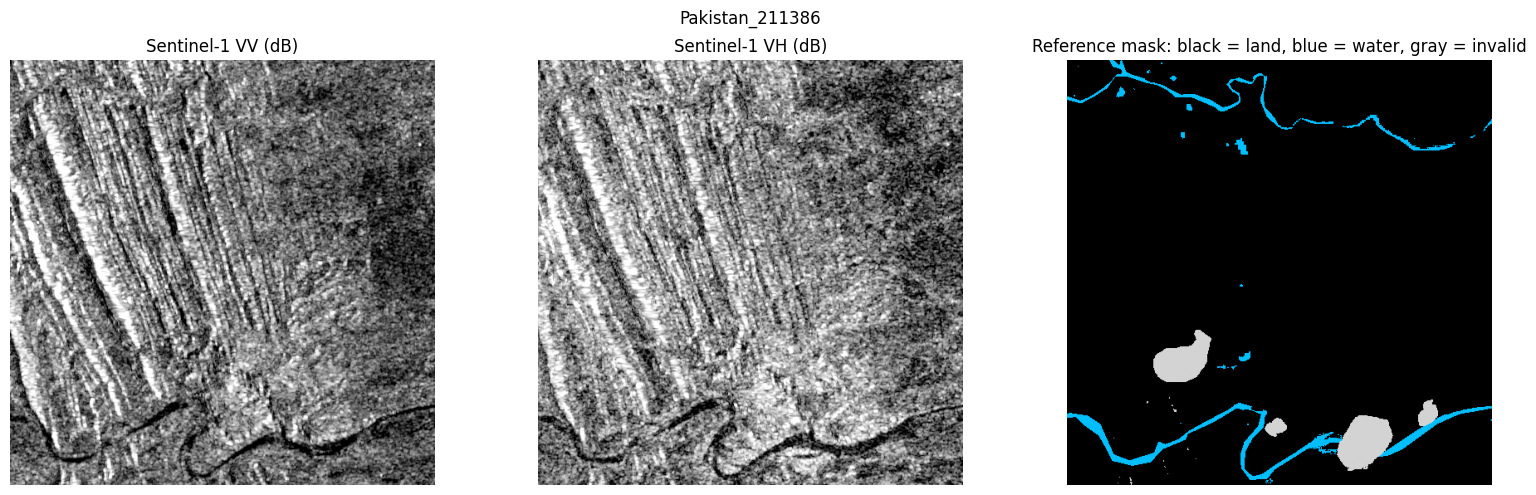

Valid pixels: 255,405 / 262,144
Water among valid pixels: 2.69%
Invalid pixels: 2.57%


In [ ]:
with rasterio.open(image_path) as src:
    sar = src.read()

with rasterio.open(label_path) as src:
    mask = src.read(1)

def display_badn(band):
    valid = np.isfinite(band)
    lo, hi = np.percentile(band[valid], [2, 98])
    return np.clip((band - lo) / (hi - lo + 1e-8), 0, 1)



fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(display_band(sar[0]), cmap="gray")
axes[0].set_title("Sentinel-1 VV (dB)")

axes[1].imshow(display_band(sar[1]), cmap="gray")
axes[1].set_title("Sentinel-1 VH (dB)")

shown_mask = np.ma.masked_where(mask == -1, mask) # -1 is the invalid pixels
cmap = ListedColormap(["black", "deepskyblue"])
cmap.set_bad("lightgray")

axes[2].imshow(shown_mask, cmap=cmap, vmin=0, vmax=1)
axes[2].set_title("Reference mask: black = land, blue = water, gray = invalid")

for ax in axes:
    ax.axis("off")

plt.suptitle(chip_id)
plt.tight_layout()
plt.show()

valid = mask != -1
print(f"Valid pixels: {valid.sum():,} / {mask.size:,}")
print(f"Water among valid pixels: {(mask[valid] == 1).mean() * 100:.2f}%")
print(f"Invalid pixels: {(~valid).mean() * 100:.2f}%")

In [ ]:
train_df = pd.read_csv(splits+"flood_train_data.csv",header=None, names=["SAR", "Label"])

stats = []

for _, row in train_df.iterrows():
    image_name = row["SAR"]
    label_name = row["Label"]

    image_path = Path(SAR_data) /  image_name
    label_path = Path(Label_data) / label_name

    with rasterio.open(label_path) as src:
        mask = src.read(1)

    total = mask.size
    invalid = np.count_nonzero(mask == -1)
    water = np.count_nonzero(mask == 1)
    nonwater = np.count_nonzero(mask == 0)
    valid = water + nonwater

    stats.append({
        "image": image_name,
        "label": label_name,
        "total_pixels": total,
        "valid_pixels": valid,
        "invalid_pixels": invalid,
        "water_pixels": water,
        "nonwater_pixels": nonwater,
        "valid_pct": 100 * valid / total,
        "invalid_pct": 100 * invalid / total,
        "water_pct_all": 100 * water / total,
        "nonwater_pct_all": 100 * nonwater / total,
        "water_pct_valid": 100 * water / valid if valid else np.nan,
        "nonwater_pct_valid": 100 * nonwater / valid if valid else np.nan,
    })

stats_df = pd.DataFrame(stats)

print(f"Pairs in CSV: {len(train_df)}")
print(f"Successfully analyzed: {len(stats_df)}")

display(stats_df.head(10))

Pairs in CSV: 252
Successfully analyzed: 252


,image,label,total_pixels,valid_pixels,invalid_pixels,water_pixels,nonwater_pixels,valid_pct,invalid_pct,water_pct_all,nonwater_pct_all,water_pct_valid,nonwater_pct_valid
0,Ghana_103272_S1Hand.tif,Ghana_103272_LabelHand.tif,262144,259269,2875,1558,257711,98.903275,1.096725,0.594330,98.308945,0.600920,99.399080
1,Ghana_24858_S1Hand.tif,Ghana_24858_LabelHand.tif,262144,262144,0,484,261660,100.000000,0.000000,0.184631,99.815369,0.184631,99.815369
2,Ghana_147015_S1Hand.tif,Ghana_147015_LabelHand.tif,262144,262144,0,3530,258614,100.000000,0.000000,1.346588,98.653412,1.346588,98.653412
3,Ghana_953791_S1Hand.tif,Ghana_953791_LabelHand.tif,262144,262144,0,2772,259372,100.000000,0.000000,1.057434,98.942566,1.057434,98.942566
4,Ghana_154838_S1Hand.tif,Ghana_154838_LabelHand.tif,262144,42107,220037,0,42107,16.062546,83.937454,0.000000,16.062546,0.000000,100.000000
5,Ghana_134751_S1Hand.tif,Ghana_134751_LabelHand.tif,262144,43016,219128,0,43016,16.409302,83.590698,0.000000,16.409302,0.000000,100.000000
6,Ghana_61925_S1Hand.tif,Ghana_61925_LabelHand.tif,262144,262144,0,651,261493,100.000000,0.000000,0.248337,99.751663,0.248337,99.751663
7,Ghana_156478_S1Hand.tif,Ghana_156478_LabelHand.tif,262144,262144,0,0,262144,100.000000,0.000000,0.000000,100.000000,0.000000,100.000000
8,Ghana_144050_S1Hand.tif,Ghana_144050_LabelHand.tif,262144,23551,238593,0,23551,8.983994,91.016006,0.000000,8.983994,0.000000,100.000000
9,Ghana_49890_S1Hand.tif,Ghana_49890_LabelHand.tif,262144,262144,0,0,262144,100.000000,0.000000,0.000000,100.000000,0.000000,100.000000


In [ ]:
total_pixels = stats_df["total_pixels"].sum()
valid_pixels = stats_df["valid_pixels"].sum()
invalid_pixels = stats_df["invalid_pixels"].sum()
water_pixels = stats_df["water_pixels"].sum()
nonwater_pixels = stats_df["nonwater_pixels"].sum()

print(f"Total pixels:{total_pixels:,}")
print(f"Valid pixels:{valid_pixels:,} ({100 * valid_pixels / total_pixels:.2f}%)")
print(f"Invalid pixels:{invalid_pixels:,} ({100 * invalid_pixels / total_pixels:.2f}%)")
print(f"Water pixels:{water_pixels:,} ({100 * water_pixels / total_pixels:.2f}% of all pixels)")
print(f"Non-water pixels:{nonwater_pixels:,} ({100 * nonwater_pixels / total_pixels:.2f}% of all pixels)")
print(f"Water among valid:  {100 * water_pixels / valid_pixels:.2f}%")
print(f"Non-water among valid: {100 * nonwater_pixels / valid_pixels:.2f}%")

Total pixels:66,060,288
Valid pixels:57,303,407 (86.74%)
Invalid pixels:8,756,881 (13.26%)
Water pixels:5,447,035 (8.25% of all pixels)
Non-water pixels:51,856,372 (78.50% of all pixels)
Water among valid:  9.51%
Non-water among valid: 90.49%
